</br>
<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>Práctica 1:
        </h2>
        <h1 style="margin-top: -10px;">
            Análisis, procesamiento y validación
        </h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Minería de Datos, 2026-27
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="font-size: 1em; color: #D0D0D0;">
                        José Antonio Gámez Martín
                    </span>
                    <a href="mailto:Jose.Gamez@uclm.es" style="text-decoration: none; color: #888888; font-size: 0.8em; padding-left: 15px;">
                        ✉ Jose.Gamez@uclm.es
                    </a>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="font-size: 1em; color: #D0D0D0;">
                        Pablo Torrijos Arenas
                    </span>
                    <a href="mailto:Pablo.Torrijos@uclm.es" style="text-decoration: none; color: #888888; font-size: 0.8em; padding-left: 15px;">
                        ✉ Pablo.Torrijos@uclm.es
                    </a>
                </div>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Estudiantes
        </h3>
    </div>
    <ul style="list-style-type: none; padding-left: 28px; margin: 0;  font-size: 1.1em">
        <li>Alfredo Solis Ortiz</li>
    </ul>

</div>

## 1. Introducción

El objetivo de esta práctica es aplicar las técnicas de un flujo de trabajo de **minería de datos** para resolver un problema de **clasificación supervisada**. Se analizará un conjunto de datos sobre el rendimiento y la actividad de estudiantes universitarios para predecir la probabilidad de abandono de sus estudios.

El desarrollo abarcará desde el **análisis exploratorio** de los datos y su **preprocesamiento**, hasta el **entrenamiento** de un modelo y su **validación** robusta. 

El rendimiento de los modelos se evaluará en una competición privada en Kaggle, que abarcará esta Práctica 1 y la Práctica 2 (selección de modelos).

<div style="border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: 10px">

## 2. Carga y visualización de los datos

Se proporciona un conjunto de datos sintético que simula el rendimiento académico y la interacción de estudiantes durante su primer año. Los datos contienen una variedad de tipos de variables, valores faltantes y otros artefactos que deberán ser gestionados.

Comenzamos importando las librerías necesarias y cargando los conjuntos de datos de entrenamiento (`train`) y de prueba (`test`) para poder examinarlos:

In [2]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

df_train = pd.read_csv('uclm_student_train.csv')
df_train

,id,nombre,nacimiento,provincia,residencia_id,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,modalidad,creditos_a1,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,numero_fav,talla_zapato,color_fav,meses_matriculado,grupo_trabajo,abandono
0,CR-2018-BCG465,Berta Calderon Giménez,1995-12-02,Albacete,E1-P00-H12,Bellas Artes,Ciclo Formativo de Grado Superior,"7,09",SOCIAL,0,NaN,Tiempo completo,60,60,"8,57","4,15",~5.5 horas,3,0,2,NaN,46,40,Beige pálido,12,GR007497,0
1,TO-2014-CFB931,Celestina Font Barranco,1996-02-25,Ciudad Real,E1-P02-H17,Doble Grado Derecho-ade,PAU / Bachillerato,"6,79",Humanidades,0,NaN,Tiempo completo,60,24,"4,75",2.51,9.1,8,1,2,Situacion academica estable. Respeta las regla...,69,35,Marrón claro,6,GR003647,0
2,CR-2014-ICS169,Irene Carranza Salvador,1968-08-02,Ciudad Real,E1-P00-H16,Derecho,Mayores de 25 años,"5,00",HUMANIDADES,1,40.0,Tiempo completo,60,42,6.19,"3,11","~3,9 horas",9,0,0,Ausencias injustificadas en seminarios. No int...,16,40,Violeta claro,5,GR003040,1
3,AB-2017-ECG641,Elodia Carmona Gisbert,2000-02-10,Albacete,NaN,Medicina,Ciclo Formativo de Grado Superior,"6,41",Ciencias Puras,0,NaN,Tiempo completo,60,42,"5,14",2.51,~8.2 horas,7,3,3,Uso habitual de la plataforma Moodle. Uso habi...,68,39,Rosa oscuro,6,GR006101,0
4,CR-2013-SGC508,Sara Guillén Cornejo,1996-01-29,Ciudad Real,NaN,Ingeniería Informática,PAU / Bachillerato,"9,05",cientifico,0,NaN,Tiempo completo,60,6,"2,68","1,16",~6.2 horas,1,2,0,Uso habitual de la plataforma Moodle. Interacc...,95,37,Violeta intenso,6,GR002005,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41081,TO-2018-GDM832,Gala de Meléndez,2000-07-15,Toledo,NaN,Comunicación Audiovisual,Ciclo Formativo de Grado Superior,"7,42",Económico,0,NaN,Tiempo completo,60,48,"6,55","3,29",~5.4 horas,4,2,0,Barreras de conciliacion con el desplazamiento...,89,36,Salmón claro,12,GR008301,0
41082,CU-2014-MCB088,Maximino Campoy Benítez,1996-11-20,Cuenca,NaN,Derecho,PAU / Bachillerato,"11,08",ECONÓMICO,0,NaN,Tiempo parcial,36,36,"7,31","3,58",~7.4 horas,0,2,1,Cumple siempre con trabajos. Contacta por corr...,13,47,Índigo pálido,6,GR003339,0
41083,CR-2015-XL601,Xavier Landa-Galván,1969-04-11,Álava,NaN,Ingeniería Mecánica,Mayores de 25 años,"7,78",ciencias puras,1,25.0,Tiempo completo,60,60,"5,65","2,67",~9.2 horas,5,2,2,No asiste a seminarios. Participacion moderada...,58,43,Marrón oscuro,6,GR004337,1
41084,CR-2012-BOI015,Begoña Olivares Iriarte,1995-01-31,Toledo,NaN,Historia del Arte,PAU / Bachillerato,7.74,Humanidades,0,NaN,Tiempo parcial,36,30,"7,15","4,13",~9.1 horas,6,3,2,NaN,23,34,Violeta pálido,6,GR000405,0


In [3]:
df_test = pd.read_csv('uclm_student_test.csv')
df_test

,id,nombre,nacimiento,provincia,residencia_id,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,modalidad,creditos_a1,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,numero_fav,talla_zapato,color_fav,meses_matriculado,grupo_trabajo
0,CU-2019-RFV844,Remigio Ferrera Vázquez,2001-03-27,Cuenca,NaN,Doble Grado Derecho-ade,PAU / Bachillerato,"8,68",SOCIAL,0,NaN,Tiempo completo,60,48,6.80,"3,46",~6.7 horas,3,2,2,Incomparecencia en las sesiones de seguimiento...,55,39,Ocre claro,12,GR009189
1,AB-2020-RR266,Rosalía Rojas,2002-07-23,Ciudad Real,E1-P03-H14,Comunicación Audiovisual,Ciclo Formativo de Grado Superior,"8,27",SOCIAL,1,40.0,Tiempo completo,60,60,"8,07","3,92",5.5,11,2,1,Uso del entorno virtual sin particularidades. ...,35,38,Granate,8,GR009871
2,CR-2019-FFC269,Felicia Ferreras Colom,2002-01-05,Ciudad Real,NaN,Criminología,Ciclo Formativo de Grado Superior,"5,00",humanidades,0,NaN,Tiempo completo,60,60,8.64,"4,57",~6.5 horas,2,3,2,Gestion ejemplar de el cuidado familiar. Adher...,22,36,Caqui oscuro,12,GR008954
3,AB-2020-OFC312,Ofelia Ferrández Carranza,2002-12-14,Badajoz,NaN,Administración y Dirección de Empresas,PAU / Bachillerato,"9,10",humanidades,1,40.0,Tiempo completo,60,30,"4,45","2,25",7.4,3,2,1,Uso del entorno virtual sin particularidades. ...,6,40,Lima oscuro,10,GR009879
4,CR-2019-MRP759,Máxima Rosselló Palomares,2001-10-27,Ciudad Real,NaN,Ingeniería Mecánica,PAU / Bachillerato,8.61,Ciencias,0,NaN,Tiempo completo,60,24,"2,95","1,41",~8.3 horas,3,0,1,incidencias registradas en el programa de ment...,14,37,Turquesa intenso,8,GR009056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11229,CU-2019-FP888,Fanny Pedrero,2001-02-23,Cuenca,NaN,Maestro en Educación Primaria,Ciclo Formativo de Grado Superior,"6,48",ECONÓMICO,0,NaN,Tiempo completo,60,60,8.53,4.33,~2.3 horas,0,3,2,No supera los minimos de la materia basica. Ad...,54,38,Magenta intenso,6,GR009181
11230,CU-2019-MBT460,Miriam Baeza Torralba,2001-04-12,Girona,NaN,Doble Grado Ade-estudios Internacionales,PAU / Bachillerato,"8,58",Económico,0,NaN,Tiempo parcial,30,12,"4,30","2,33",~6.7 horas,5,2,0,NaN,15,38,Plata,11,GR009205
11231,CR-2019-EJF437,Enrique Juliá Fabra,1995-01-26,Ciudad Real,E1-P02-H11,Derecho,Titulado universitario,"8,15",economico,0,NaN,Tiempo completo,60,60,"8,30","4,20","4,1h",4,4,3,NaN,24,46,Magenta,11,GR008919
11232,CR-2019-CAP408,Chema Alejo Peláez Mas,2001-07-08,NaN,E2-P02-H09,"Lenguas y Literaturas Modernas, Francés-inglés",Ciclo Formativo de Grado Superior,"7,22",Social,0,NaN,Tiempo completo,60,60,"8,68","4,67",~6.5 horas,6,1,1,Se ofrece como referente para estudiantes de n...,23,44,Negro,12,GR008774


Las variables disponibles son:
`id`, `nombre`, `nacimiento`, `provincia`, `residencia_id`, `titulacion`, `via_acceso`, `nota_acceso`, `bachillerato`, `trabaja`, `horas_trabajo`, `modalidad`, `creditos_a1`, `superados_a1`, `nota_s1`, `satisfaccion`, `horas_moodle`, `uso_biblioteca`, `eventos`, `tutorias`, `comentarios`, `numero_fav`, `talla_zapato`, `color_fav`, `meses_matriculado`, `grupo_trabajo`, `abandono`.

La variable objetivo es `abandono`, que es binaria:
* **1**: El estudiante abandona los estudios.
* **0**: El estudiante continúa.

Se puede observar cómo hay variables categóricas, numéricas, fechas, texto, valores faltantes... Esto requerirá de un análisis exploratorio y un preprocesamiento.

<div style="border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: 10px">

## 3. Flujo de Trabajo y Requisitos

El desarrollo de la práctica deberá seguir las siguientes etapas:


### 3.1. Análisis Exploratorio de Datos (EDA)

Se debe realizar un análisis inicial para comprender la naturaleza de los datos. Este análisis debe incluir:
* Distribución de la variable objetivo (`abandono`).
* Análisis de valores faltantes.
* Distribución de las variables numéricas y categóricas, valores únicos, outliers...
* Identificación de valores atípicos.
* Relaciones entre las variables y la variable objetivo.

Las conclusiones de este análisis deben servir para justificar las decisiones tomadas en la siguiente etapa.


### 3.2. Preprocesamiento de Datos

Esta etapa es fundamental para preparar los datos antes de la modelización. Las tareas incluyen la imputación de valores faltantes, la codificación de variables categóricas, la ingeniería de características (ej. creación de nuevas variables a partir de las existentes), el escalado de datos o incluso eliminar variables que no nos aporten información.

Este proceso debe de ir totalmente ligado al EDA. Las conclusiones que hayamos sacado en el estudio son las que nos deben guiar en este paso. Del mismo modo, al preprocesar los datos y entrenar los modelos podemos sacar nuevas conclusiones que nos permitan entender mejor los datos (como habéis visto en **CRISP-DM**):

<img src="https://upload.wikimedia.org/wikipedia/commons/b/b9/CRISP-DM_Process_Diagram.png" alt="Diagrama de Proceso CRISP-DM" width="550"/>

**Requisito obligatorio**: Todo el proceso de transformación de datos **debe** encapsularse en `Pipelines` de `scikit-learn`. En la práctica, además de mantener una mayor claridad y estructura en el código, esto nos ayudará a evitar fugas de datos.


### 3.3. Modelización y Validación

Se debe entrenar y evaluar correctamente **al menos un algoritmo** (ej. Árboles de Decisión, Naive Bayes, etc.). En esta práctica no es importante usar el mejor modelo posible (eso vendrá en la Práctica 2), sino analizar, preparar y evaluar bien los datos.

**Requisito obligatorio**: La evaluación y comparación de los modelos **debe** realizarse mediante una estrategia de **validación cruzada**. Además, es importante tener en cuenta distintas **métricas** para evaluar nuestro modelo.


### 3.4. Predicción y Evaluación

El modelo final se puede utilizar para generar predicciones sobre el conjunto `uclm_student_test.csv`. Esto es recomendable, pero no es obligatorio en esta práctica (lo será en la Práctica 2).

El fichero de predicciones deberá seguir el formato especificado en `sample_submission.csv`:

In [4]:
df_kaggle = pd.read_csv('sample_submission.csv')
df_kaggle

,id,abandono
0,CU-2019-RFV844,0
1,AB-2020-RR266,1
2,CR-2019-FFC269,0
3,AB-2020-OFC312,0
4,CR-2019-MRP759,1
...,...,...
11229,CU-2019-FP888,0
11230,CU-2019-MBT460,0
11231,CR-2019-EJF437,0
11232,CR-2019-CAP408,0


<div style="border-bottom: 2px solid #555555; margin-bottom: 10px">

## 4. Competición en Kaggle

La evaluación final se realizará mediante una competición privada en Kaggle. El objetivo es maximizar la métrica **F1-Score**, una medida robusta que tiene en cuenta tanto la precisión como la exhaustividad, especialmente útil en casos con clases desbalanceadas.

* **Enlace a la competición**: []()

Los equipos con mejor rendimiento en el *private leaderboard* recibirán una bonificación en la nota final:
* **1er puesto**: +0.75 puntos.
* **2º puesto**: +0.5 puntos.
* **3er puesto**: +0.25 puntos.

**Nota**: Las bonificaciones están sujetas a la revisión del código y la metodología. Se podrá requerir una justificación del enfoque para verificar la originalidad y la comprensión del trabajo.

## 5. Análisis exploratorio de datos 
### 5.1 Distribución de la variable objetivo

abandono vale 0(continua) o 1(abandona) cuantos estudiantes hay de cada clase y en que proporcion ?

In [5]:
#Imports necesarios
import matplotlib.pyplot as plt 
import seaborn as sns


In [6]:
#Conteo y faltantes

df_train['abandono'].value_counts(dropna=False)
#si hubiera faltantes apareceria una fila NaN con su conteo


abandono
0    26969
1    14117
Name: count, dtype: int64

In [7]:
#Porcentajes
(df_train['abandono'].value_counts(normalize=True) * 100).round(3)
#normalize=True, divide cada conteo entre el total de fila, asi obtenemos proporciones


abandono
0    65.64
1    34.36
Name: proportion, dtype: float64

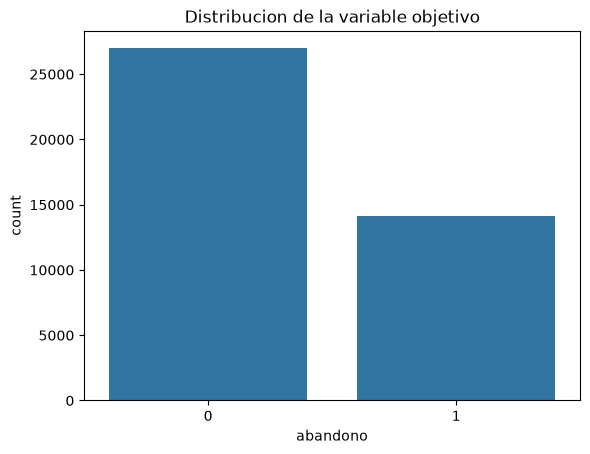

In [8]:

#grafico
sns.countplot(data=df_train, x='abandono')
plt.title('Distribucion de la variable objetivo')
plt.show()

#### Conclusion 5.1 

Entonces : ¿Como se reparte la variable objetivo y que implica para el modelo? 

De los 41086 estudiantes, 26969 continuan(65.6%) y 14117 abandonan (34.4%) y no hay valores faltantes en abandono. Las clases están desbalanceadas, asi que la accuracy no es una buena metrica, diciendo siempre 'continua' ya se acertaría un 65%, por eso usaremos el F1 y validación cruzada.

Estos datos incluyen filas duplicadas, sin ellas la tasa de abandono baja al 27.3% (Consultar 5.5)

### 5.2 Analisis de Valores faltantes

In [9]:
#verificar valores faltantes en todas las columnas 

df_train.isna().sum()

id                       0
nombre                   0
nacimiento               0
provincia             2512
residencia_id        30128
titulacion               0
via_acceso               0
nota_acceso              0
bachillerato             0
trabaja                  0
horas_trabajo        36028
modalidad                0
creditos_a1              0
superados_a1             0
nota_s1               2424
satisfaccion          2424
horas_moodle             0
uso_biblioteca           0
eventos                  0
tutorias                 0
comentarios           8220
numero_fav               0
talla_zapato             0
color_fav                0
meses_matriculado        0
grupo_trabajo            0
abandono                 0
dtype: int64

In [10]:
#lo pasamos a porcentaje, faltante del total de cada dato

(df_train.isna().mean()*100).sort_values(ascending=False)

horas_trabajo        87.689237
residencia_id        73.329115
comentarios          20.006815
provincia             6.114005
nota_s1               5.899820
satisfaccion          5.899820
id                    0.000000
horas_moodle          0.000000
grupo_trabajo         0.000000
meses_matriculado     0.000000
color_fav             0.000000
talla_zapato          0.000000
numero_fav            0.000000
tutorias              0.000000
eventos               0.000000
uso_biblioteca        0.000000
superados_a1          0.000000
nombre                0.000000
creditos_a1           0.000000
modalidad             0.000000
trabaja               0.000000
bachillerato          0.000000
nota_acceso           0.000000
via_acceso            0.000000
titulacion            0.000000
nacimiento            0.000000
abandono              0.000000
dtype: float64

In [11]:
# por que falta tanto horas de trabajo? 

df_train['trabaja'].value_counts(normalize=True)*100

trabaja
0    82.578007
1    17.421993
Name: proportion, dtype: float64

In [12]:
#comparacion trabaja y horas de trabajo

pd.crosstab(df_train['trabaja'], df_train['horas_trabajo'].isna())

horas_trabajo,False,True
trabaja,,
0,0,33928
1,5058,2100


In [13]:
#mediana o media ?

df_train['horas_trabajo'].describe() #describe ignora los NaN, hay que fijarnos en el minimo, maximos, la media y la mediana 

count    5058.000000
mean       23.532028
std         9.899888
min        10.000000
25%        15.000000
50%        25.000000
75%        30.000000
max        40.000000
Name: horas_trabajo, dtype: float64

In [14]:
#importa el hueco para predecir ??

df_train.groupby(['trabaja', df_train['horas_trabajo'].isna()])['abandono'].mean()

trabaja  horas_trabajo
0        True             0.324894
1        False            0.432187
         True             0.432381
Name: abandono, dtype: float64


  Falta en el 87,7 % de las filas, pero casi todo tiene explicación:
  los 33.928 estudiantes que no 
  trabajan no tienen horas porque 
  no aplica, así que se rellenan 
  con 0. Los 2.100 que trabajan y 
  no tienen horas sí son datos 
  perdidos, y se rellenan con la 
  mediana de los que trabajan (25 
  horas); la media (23,5) es 
  parecida, pero la mediana es un 
  valor que existe en los datos. El
  hueco no aporta información 
  (43,2 % de abandono con o sin 
  horas), así que no hace falta 
  marcarlo. Además, los que 
  trabajan abandonan más (43,2 %) 
  que los que no (32,5 %), así que 
  'trabaja' parece útil.

### Ahora aplicamos el mismo proceso para 'residencia_id'


In [15]:
df_train['residencia_id'].value_counts()

residencia_id
E3-P00-H17    62
E3-P02-H10    55
E1-P00-H14    54
E2-P04-H01    53
E2-P00-H20    50
              ..
E1-P01-H04    23
E3-P02-H07    23
E2-P04-H19    22
E3-P04-H03    21
E3-P02-H12    20
Name: count, Length: 300, dtype: int64

In [16]:
df_train['residencia_id'].nunique()
#pensamos en dos cosas, el formato de los codigos de residencia
#cuantos estudiantes comparten cada codigo?
#alta cardinalidad, es categorica con muchas categorias

300

In [17]:
#importa tener residencia o no ?

df_train.groupby(df_train['residencia_id'].isna())['abandono'].mean()

#donde True es la tasa de abandono de los que no tienen residencia y False de los que si
#cambia muy poco, vivir o no en residencia, no cambia la probabilidad de abandonar

residencia_id
False    0.345045
True     0.343070
Name: abandono, dtype: float64

### **Que se concluye hasta ahora ?**

-> Un 73% sin codigo significa que eso estudiantes no viven en residencia, lo mejor seria tratarlos como categoria propia, 'sin residencia'

-> Tener o no residencia no predice nada, segun la tabla anterior

#### A pesar de esto queda una pregunta por comprobar, importa en cual de las 300 residencia vivan ?

In [18]:
df_train.groupby('residencia_id')['abandono'].agg(['mean', 'count']).sort_values('mean')
#donde .agg(['mean', 'count']) calcula dos cosas por residencia: la tasa de abandono y cuantos estudiantes tiene

,mean,count
residencia_id,,
E1-P03-H08,0.050000,40
E2-P02-H12,0.100000,30
E3-P02-H11,0.133333,30
E2-P03-H14,0.135135,37
E2-P02-H20,0.161290,31
...,...,...
E3-P04-H20,0.558824,34
E1-P00-H06,0.562500,32
E3-P03-H06,0.594595,37


#### **Conclusión: 'residencia_id'**

Falta en el 73,3 % de las filas (30.128 de 41.086). El hueco no es un dato perdido: indica que el estudiante no vive en residencia.

* **Tipo de variable:** aunque se llama "id", no identifica a una persona. Hay 300 códigos distintos con formato edificio-planta-habitación 
(por ejemplo 'E3-P00-H17'), cada uno compartido por entre 20 y 62 estudiantes. Es una variable categórica de alta cardinalidad.
* **¿Importa tener o no residencia?** No. La tasa de abandono es del 34,5 % entre los que viven en residencia y del 34,3 % entre los que no.
* **¿Importa la residencia concreta?** La tasa de abandono por código va del 5 % al 65 %, pero cada grupo tiene muy pocos estudiantes, así que 
gran parte de esa variación se debe al azar y no a un efecto real de la residencia.

* **Decisión para el preprocesamiento:** eliminar la columna. Tener o no residencia no aporta información, y mantener los 300 códigos añadiría 
muchas columnas con pocos datos en cada una y riesgo de que el modelo memorice ruido.

### Pasamos con las variables 'nota_s1' y 'satisfaccion'

Vemos que en la parte de faltantes ambas tienen el mismo porcentaje de faltantes (5.899820%)

In [19]:
(df_train['nota_s1'].isna() & df_train['satisfaccion'].isna()).sum()
#aqui se devuelve el numero de filas donde faltan nota_s1 y satisfaccion a la vez

np.int64(2424)

In [20]:
df_train.groupby(df_train['nota_s1'].isna())['abandono'].mean()
#aqui se vera que los estudiantes sin nota abandonan casi el doble que los que la tienen

nota_s1
False    0.326134
True     0.622112
Name: abandono, dtype: float64

#### **Conclusión: nota_s1 y satisfaccion**

Cada una falta en el 5,9 % de las filas (2.424 de 41.086), y faltan exactamente en las mismas: no hay ningún estudiante que tenga una y no la 
otra. No es casualidad; algo hizo que a esos estudiantes no se les registrara ninguno de los dos datos.

* **¿Aporta información el hueco?** Sí, y mucha. Los estudiantes sin nota del primer semestre abandonan en un 62,2 %, frente al 32,6 % de los 
que sí la tienen: casi el doble.
* **Posible explicación:** probablemente son estudiantes que no se presentaron a los exámenes o dejaron de asistir durante el primer semestre, 
    por lo que no tienen nota ni respondieron a la encuesta de satisfacción. Aun así, un 38 % de ellos continúa, así que el hueco es una señal 
  fuerte pero no equivale a abandonar.
* **¿Por qué no rellenar con 0?** Un 0 es una nota posible (presentarse y suspender), así que se mezclarían estudiantes sin nota con 
  estudiantes con la peor nota, y se distorsionaría la distribución de la variable.
* **¿Por qué no solo la mediana?** Esos estudiantes pasarían a parecer alumnos normales y se perdería la información más útil encontrada hasta 
  ahora.

  **Decisión para el preprocesamiento:** crear una columna nueva que marque con 1 a los estudiantes sin nota del primer semestre, e imputar la 
  mediana en 'nota_s1' y 'satisfaccion'. Basta con una sola columna de marca, porque las dos variables faltan siempre juntas.

### **Ahora las variables 'comentarios' y 'provincia'**

In [21]:
df_train.groupby(df_train['comentarios'].isna())['abandono'].mean()

comentarios
False    0.345037
True     0.337835
Name: abandono, dtype: float64

In [22]:
df_train.groupby(df_train['provincia'].isna())['abandono'].mean()

provincia
False    0.343807
True     0.340366
Name: abandono, dtype: float64

In [23]:
df_train['provincia'].value_counts()

provincia
Ciudad Real               9800
Toledo                    9313
Albacete                  8920
Cuenca                    6288
Jaén                       114
Palencia                   106
Cádiz                      102
Santa Cruz de Tenerife     101
Valencia                   100
Zaragoza                   100
Cantabria                   99
León                        99
Girona                      98
Baleares                    98
Soria                       96
Huelva                      95
Cáceres                     95
Teruel                      95
Las Palmas                  93
Burgos                      93
Huesca                      93
Salamanca                   92
Lleida                      91
Ávila                       91
Segovia                     91
Ourense                     91
Ceuta                       90
Almería                     90
Navarra                     90
Málaga                      89
Vizcaya                     88
Guipúzcoa                   8

In [24]:
df_train['comentarios'].head(15)
# aqui hacemos dos preguntas: importa que el comentario falte ? No
#importa lo que dice el comentario? Si y bastante

0                                                   NaN
1     Situacion academica estable. Respeta las regla...
2     Ausencias injustificadas en seminarios. No int...
3     Uso habitual de la plataforma Moodle. Uso habi...
4     Uso habitual de la plataforma Moodle. Interacc...
5     No asiste a clase. Situacion academica estable...
6     dificultades para compaginar asistencia y tare...
7     Muestra gran interes por fisica. Expresa dudas...
8     Situacion academica estable. Situacion academi...
9                                                   NaN
10    Uso habitual de la plataforma Moodle. uso habi...
11    Participacion moderada en clase. Participacion...
12    Cumple siempre con trabajos. Perfil de alumno ...
13    Uso del entorno virtual sin particularidades. ...
14    expresa dudas sobre la titulacion. Se detectan...
Name: comentarios, dtype: str

  #### **Conclusión: Comentarios y provincia**

  * **provincia** (6,1 % de
  huecos): el hueco no cambia el
  abandono (34,0 % frente a 34,4
  %). No se rellena con la
  provincia más frecuente porque
  Ciudad Real, Toledo y Albacete
  tienen tamaños parecidos y se
  inflaría una de ellas; se usará
  una categoría nueva,
  "Desconocida".
  * **comentarios** (20 % de
  huecos): son observaciones sobre
  el estudiante. Que falte el
  comentario no cambia el abandono
  (33,8 % frente a 34,5 %), así que
  se rellena con texto vacío. Lo
  que sí parece importar es lo que
  dice, y se analiza en el 5.5.

### **5.3 Distribucion de las variables numericas y categoricas y valores unicos**

In [25]:
#tipos de variables que da pandas a cada col

df_train.dtypes


id                       str
nombre                   str
nacimiento               str
provincia                str
residencia_id            str
titulacion               str
via_acceso               str
nota_acceso              str
bachillerato             str
trabaja                int64
horas_trabajo        float64
modalidad                str
creditos_a1            int64
superados_a1           int64
nota_s1                  str
satisfaccion             str
horas_moodle             str
uso_biblioteca         int64
eventos                int64
tutorias               int64
comentarios              str
numero_fav             int64
talla_zapato           int64
color_fav                str
meses_matriculado      int64
grupo_trabajo            str
abandono               int64
dtype: object

In [26]:
#Aqui buscamos el numero de valores distintos en cada columna
df_train.nunique()

id                   36715
nombre               36705
nacimiento            5843
provincia               53
residencia_id          300
titulacion              64
via_acceso               4
nota_acceso           1375
bachillerato            25
trabaja                  2
horas_trabajo            6
modalidad                2
creditos_a1              4
superados_a1            11
nota_s1               1265
satisfaccion           719
horas_moodle          1322
uso_biblioteca          17
eventos                 12
tutorias                11
comentarios          28290
numero_fav             100
talla_zapato            15
color_fav              140
meses_matriculado       12
grupo_trabajo         8382
abandono                 2
dtype: int64

In [27]:
#vemos que id tiene 36.715 valores, pero hay 41.086, veremos que pasa

df_train.duplicated().sum()

np.int64(4371)

In [28]:
# columnas sospechosas de ser numéricas guardadas como texto
df_train[['nota_acceso','nota_s1', 'satisfaccion','horas_moodle']].sample(10,random_state=1)

,nota_acceso,nota_s1,satisfaccion,horas_moodle
11998,"8,04","6,88","3,17",7.9
16016,"6,51","7,46","4,16",~7.4 horas
10634,"9,93","6,34","3,28",2.12 h
24247,"6,76",NaN,NaN,~12.9 horas
22887,8.23,"7,31","3,56","~2,8 horas"
29197,"7,98","5,11","2,67","5,4h"
8805,8.22,5.68,"2,88",~7.3 horas
20675,"10,69","8,03","3,88",~9.8 horas
41044,6.69,"5,51","3,03",~3.2 horas
31642,"9,06","4,64","2,29",~6.6 horas


#### Conclusión: tipos de variables y valores únicos

* **Numéricas:** horas_trabajo, creditos_a1, superados_a1, uso_biblioteca, eventos, tutorias, numero_fav, talla_zapato y meses_matriculado.
* **Numéricas guardadas como texto:** nota_acceso, nota_s1 y satisfaccion (mezclan coma y punto decimal) y horas_moodle (además lleva texto, como "~7.4 horas" o "5,4h"). Hay que convertirlas a número.
* **Binarias:** trabaja y abandono.
* **Categóricas:** provincia (53), titulacion (64), via_acceso (4), bachillerato (25), modalidad (2) y color_fav (140), y con muchísimos valores residencia_id (300) y grupo_trabajo (8.382).
* **Otras:** id y nombre (identificadores), nacimiento (fecha) y comentarios (texto).

Hay 4.371 filas duplicadas, por eso id tiene 36.715 valores distintos en 41.086 filas. Se eliminarán antes de entrenar.


#### Conversion de las numericas guardadas como texto

Para analizar su distribucion, convertimos 'nota_acceso', 'nota_s1', 'satisfaccion' y 'horas_moodle' a número sobre una copia de los datos(eda), sin modificar 'df_train'

In [29]:
eda = df_train.copy()

In [30]:
#celda 1: convertimos las tres columnas con coma decimal
#nota_acceso, nota_s1 y satisfaccion

for col in ['nota_acceso', 'nota_s1', 'satisfaccion']:
    eda[col] = pd.to_numeric(eda[col].str.replace(',', '.'))

In [31]:
#ahora pasamos con horas_moodle, hay que quitar todo lo que no sea numero

eda['horas_moodle'] = pd.to_numeric(
    eda['horas_moodle']
    .str.replace(',', '.')
    .str.replace('~', '')
    .str.replace('horas', '')
    .str.replace('h', '')
    .str.strip()
)
#el orden importa 'horas se quita antes que h' ya que si quitamos la h primero no podriamos quitar horas

In [32]:
#comprobamos que todo este en orden
cols_convertidas = ['nota_acceso', 'nota_s1', 'satisfaccion', 'horas_moodle']
print(eda[cols_convertidas].dtypes)
print(eda[cols_convertidas].isna().sum())

nota_acceso     float64
nota_s1         float64
satisfaccion    float64
horas_moodle    float64
dtype: object
nota_acceso        0
nota_s1         2424
satisfaccion    2424
horas_moodle       0
dtype: int64


 Vemos que efectivamente las variables ahora son detectadas como floats, pero que se ha hecho ?

convertimos las 4 columnas a numero unificado, quitamos la coma por un punto y en 'horas_moodle'
eliminamos el texto que acompañaba al numero, como no cambio el numero de valores faltantes la conversion no ha perdido nignun dato

In [33]:
#Distribucion de las numericas 

#celda 1: lista numericas y resumen

numericas = ['nota_acceso', 'nota_s1', 'satisfaccion', 'horas_moodle',
               'horas_trabajo', 'creditos_a1', 'superados_a1', 'uso_biblioteca',
               'eventos', 'tutorias', 'numero_fav', 'talla_zapato', 'meses_matriculado']

eda[numericas].describe().round(2).T

#numericas guarda en una variable la lista de col. numericas
#trabaja y abandono no van por que son binarias 
#describe() calcula para cada una el conteo, la media, la desviacion, el minimo, los cuartiles y el maximo

,count,mean,std,min,25%,50%,75%,max
nota_acceso,41086.0,8.29,1.37,5.00,7.35,8.32,9.24,13.68
nota_s1,38662.0,6.76,1.26,0.92,5.92,6.98,7.75,9.94
satisfaccion,38662.0,3.38,0.65,0.36,2.95,3.48,3.88,4.95
horas_moodle,41086.0,6.58,2.54,0.20,4.80,6.60,8.30,16.90
horas_trabajo,5058.0,23.53,9.90,10.00,15.00,25.00,30.00,40.00
creditos_a1,41086.0,58.82,5.29,30.00,60.00,60.00,60.00,60.00
superados_a1,41086.0,48.55,12.38,0.00,42.00,54.00,60.00,60.00
uso_biblioteca,41086.0,4.38,2.30,0.00,3.00,4.00,6.00,16.00
eventos,41086.0,1.96,1.59,0.00,1.00,2.00,3.00,11.00
tutorias,41086.0,1.63,1.31,0.00,1.00,1.00,2.00,10.00


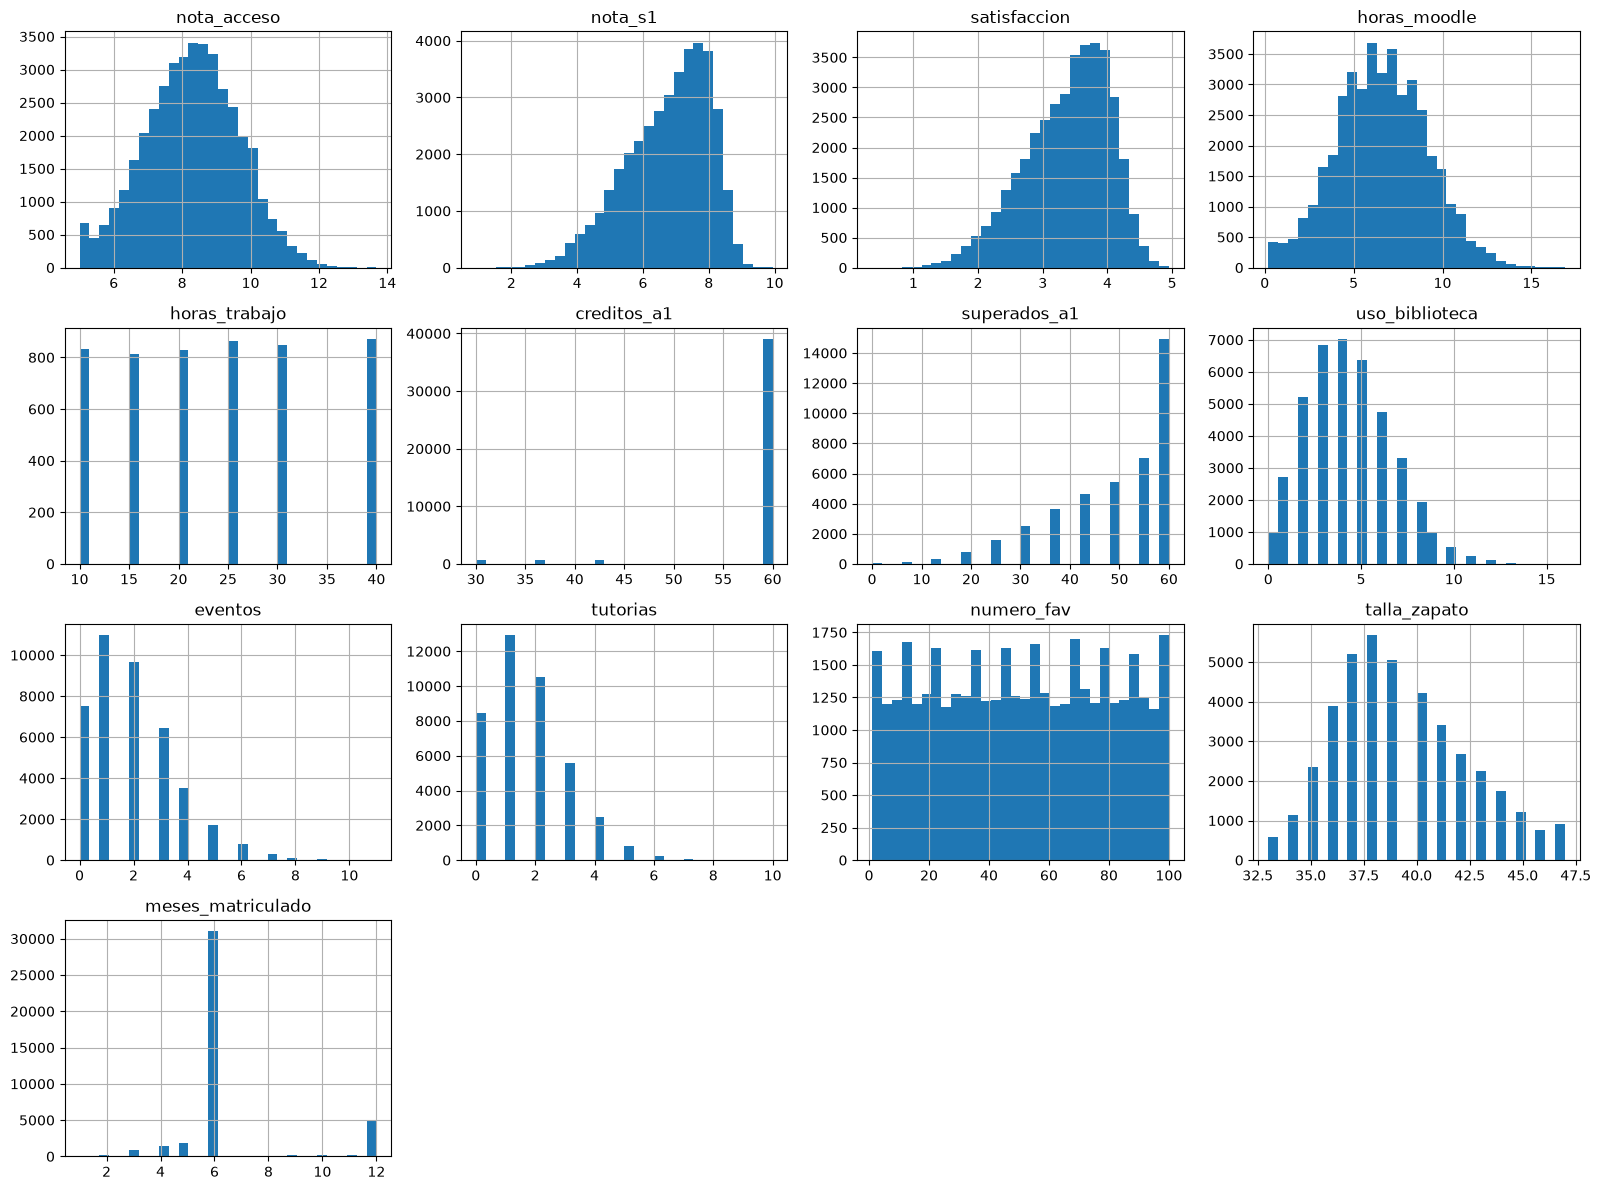

In [34]:
#celda 2: histogramas numericas


eda[numericas].hist(bins=30, figsize=(16, 12))
plt.tight_layout()
plt.show()


#### Conclusión: distribución de las variables numéricas

* **Forma de campana:** nota_acceso y horas_moodle son casi simétricas, con la media igual a la mediana (8,3 y 6,6). nota_s1 y satisfaccion también, pero con una cola hacia las notas bajas.
* **Cola a la derecha:** uso_biblioteca, eventos y tutorias son conteos. La mayoría tiene valores bajos y unos pocos llegan a 10 o más.
* **Concentradas en un valor:** creditos_a1 vale 60 en el 95 % de las filas y superados_a1 tiene un pico en 60 (36 % lo aprueba todo). meses_matriculado se concentra en 6 y 12.
* **Pocos valores:** horas_trabajo solo toma 6 valores (10, 15, 20, 25, 30 y 40), con un número parecido de estudiantes en cada uno.
* **Planas:** numero_fav reparte a los estudiantes por igual entre 1 y 100, lo que hace pensar que es aleatoria (se comprueba en el 5.5).

Las escalas son muy distintas (de 0 a 5 en satisfaccion, de 30 a 60 en créditos), así que habrá que escalar las numéricas en el preprocesamiento.


### Variables categóricas y valores unicos

In [35]:
#comprobar valores unicos de las categorias 

categoricas = ['provincia', 'titulacion', 'via_acceso', 'bachillerato', 'modalidad', 'color_fav']
eda[categoricas].nunique()
#guardaremos la lista de categoricas en una variable para reutilizarla

provincia        53
titulacion       64
via_acceso        4
bachillerato     25
modalidad         2
color_fav       140
dtype: int64

In [36]:
#vemos que 'via_acceso' y 'modalidad' tienen pocos valores 

for col in ['via_acceso', 'modalidad']:
    print(eda[col].value_counts(), '\n')

via_acceso
PAU / Bachillerato                   28561
Ciclo Formativo de Grado Superior     8680
Mayores de 25 años                    2160
Titulado universitario                1685
Name: count, dtype: int64 

modalidad
Tiempo completo    39068
Tiempo parcial      2018
Name: count, dtype: int64 



In [37]:
#ahora para 'bachillerato'

eda['bachillerato'].value_counts()

bachillerato
Ciencias Sociales       2651
Humanidades             2581
HUMANIDADES             2556
Social                  2528
SOCIAL                  2494
humanidades             2474
ECONÓMICO               2312
Económico               2273
economico               2188
CIENCIAS PURAS          1995
ciencias puras          1972
Ciencias Puras          1906
Científico              1546
Ciencias                1530
cientifico              1491
CIENTÍFICO              1486
TECNOLÓGICO             1229
tecnologico             1202
Tecnológico             1164
Salud                    830
CIENCIAS DE LA SALUD     795
Ciencias de la Salud     782
Artes                    396
artistico                369
ARTES                    336
Name: count, dtype: int64

In [38]:
#hay algo que notamos y es que muchos son el mismo escrtio de otra forma: TECNOLOGICO, tecnologico y Tecnologico, por ejemplo

#para esto hay que unificar mayusuculas, minusculas y tildes


(eda['bachillerato']
    .str.strip()
    .str.lower()
    .str.normalize('NFKD')
    .str.encode('ascii', errors='ignore')
    .str.decode('ascii')
    .value_counts())

#aqui cada linea hace una limpieza sobre la anterior

bachillerato
humanidades             7611
economico               6773
ciencias puras          5873
social                  5022
cientifico              4523
tecnologico             3595
ciencias sociales       2651
ciencias de la salud    1577
ciencias                1530
salud                    830
artes                    732
artistico                369
Name: count, dtype: int64

Bueno y es verdad que pasamos de 25 a 12 valores, y vemos que a pesar de eso quedan valores similares como 'salud' y 'ciencias de la salud' o 'social' y 'ciencias sociales'

In [39]:
#resto de categoricas con muchos valores

for col in ['provincia', 'titulacion', 'color_fav']:
    conteo = eda[col].value_counts()
    print(f'--- {col}: {len(conteo)} valores ---')
    print('Más frecuentes:')
    print(conteo.head(5))
    print('Menos frecuentes:')
    print(conteo.tail(5), '\n')



--- provincia: 53 valores ---
Más frecuentes:
provincia
Ciudad Real    9800
Toledo         9313
Albacete       8920
Cuenca         6288
Jaén            114
Name: count, dtype: int64
Menos frecuentes:
provincia
Guadalajara    72
Lugo           71
Sevilla        70
Pontevedra     68
Alicante       68
Name: count, dtype: int64 

--- titulacion: 64 valores ---
Más frecuentes:
titulacion
Maestro en Educación Primaria             3510
Administración y Dirección de Empresas    3458
Enfermería                                3374
Derecho                                   3085
Ingeniería Informática                    2258
Name: count, dtype: int64
Menos frecuentes:
titulacion
Ingeniería Minera y Energética           48
Ingeniería Civil y Territorial           47
Humanidades: Historia Cultural           30
Geografía y Ordenación del Territorio    17
Ingeniería de Edificación                13
Name: count, dtype: int64 

--- color_fav: 140 valores ---
Más frecuentes:
color_fav
Granate intenso    

In [40]:
#valor de 'ciudad'

eda['provincia'].value_counts()['Ciudad']

np.int64(77)

In [41]:
#comprobar  'modalidad' frente a 'creditos_a1'

tabla = pd.crosstab(eda['modalidad'], eda['creditos_a1'], margins=True, margins_name='Total')
tabla.columns = [f'{c} créditos' if c != 'Total' else c for c in tabla.columns]
tabla.index.name = None
tabla.columns.name = 'Modalidad'
tabla


Modalidad,30 créditos,36 créditos,42 créditos,60 créditos,Total
Tiempo completo,0,0,0,39068,39068
Tiempo parcial,676,653,689,0,2018
Total,676,653,689,39068,41086


#### Conclusión: distribución de las variables categóricas

* **via_acceso:** la mayoría entra por PAU / Bachillerato; Mayores de 25 y Titulados son minoría.
* **modalidad y creditos_a1:** son redundantes, porque tiempo completo siempre tiene 60 créditos y tiempo parcial 30, 36 o 42. Basta con una.
* **bachillerato:** tiene 25 formas de escribir 7 categorías (mayúsculas, tildes y sinónimos como "salud" y "ciencias de la salud"). Hay que unificarlas.
* **provincia:** casi todos son de Ciudad Real, Toledo, Albacete y Cuenca. Hay un valor "Ciudad" (77 filas) que es "Ciudad Real" cortado.
* **titulacion:** muy desigual, de 3.510 estudiantes a 13.
* **color_fav:** los 140 colores tienen un número parecido de estudiantes; parece aleatoria.


### 5.4 Identificación de valores atípicos

Un valor atípico es un valor muy alejado de donde se concentra la mayoría de los datos. Puede ser un error (una nota de 25, unas horas negativas...), que habría que corregir, o un caso real poco frecuente.

Para detectarlos usamos la regla del IQR: se calculan los cuartiles Q1 (25 %) y Q3 (75 %), y se considera atípico todo valor por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR, donde IQR = Q3 − Q1.

Seguimos 4 pasos:

1. **Diagramas de caja:** ver en qué variables hay valores alejados.
2. **Tabla IQR:** calcular los límites y contar los atípicos de cada variable.
3. **Valores imposibles y coherencia:** comprobar si algún valor está fuera de lo posible, es decir, si es un error.
4. **Conteos ordenados:** ver si los atípicos forman una cola natural o son valores aislados.

El objetivo es decidir si los atípicos se eliminan o se conservan en el preprocesamiento.


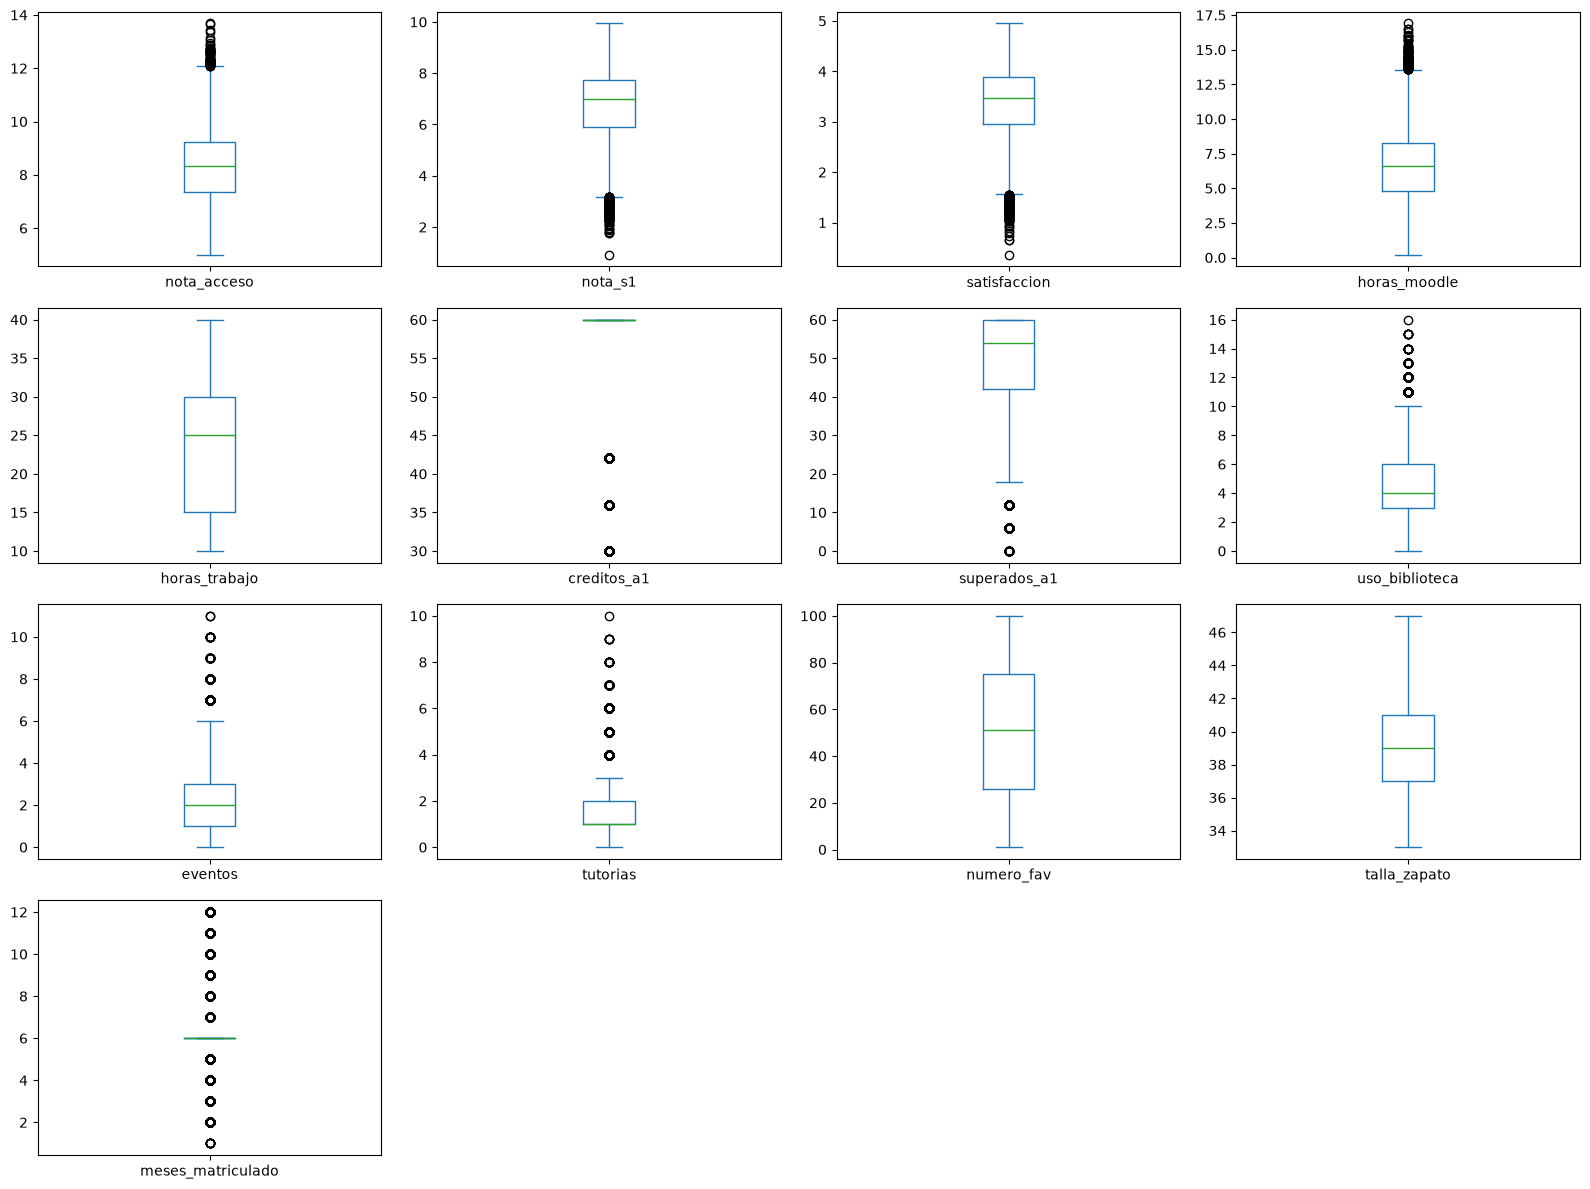

In [42]:
#lo primero que haremos seran diagramas de cajas, donde cada diagrama mostrara una caja que va del cuartil Q1 a Q3, con la mediana como linea interior
#Los bigotes llegaran hasta los limites de la regla del IQR y los circulos que quedan fuera son los candidatos a atipicos

eda[numericas].plot(kind='box', subplots=True, layout=(4, 4), figsize=(16, 12))
plt.tight_layout()
plt.show()



#### Qué se observa en los diagramas de caja

Hay candidatos a atípicos en tres situaciones:

* **Por arriba:** nota_acceso, horas_moodle y los conteos (uso_biblioteca, eventos y tutorias).
* **Por abajo:** nota_s1, satisfaccion y superados_a1.
* **Caja aplastada en una línea:** creditos_a1 y meses_matriculado. Casi todos tienen el mismo valor, así que cualquier otro aparece como atípico.

horas_trabajo, numero_fav y talla_zapato no tienen atípicos.


#### Tabla IQR

Calculamos los límites de la regla para las 13 variables numéricas y contamos cuántos valores quedan fuera.


In [43]:
#Limites del IQR y numero de atipicos de cada variable numerica

q1 = eda[numericas].quantile(0.25)
q3 = eda[numericas].quantile(0.75)
iqr = q3 - q1

fuera = (eda[numericas] < q1 - 1.5 * iqr) | (eda[numericas] > q3 + 1.5 * iqr)

pd.DataFrame({
    'q1': q1,
    'q3': q3,
    'limite_inf': q1 - 1.5 * iqr,
    'limite_sup': q3 + 1.5 * iqr,
    'n_atipicos': fuera.sum(),
    '%': (fuera.mean() * 100).round(2),
}).round(2)

,q1,q3,limite_inf,limite_sup,n_atipicos,%
nota_acceso,7.35,9.24,4.51,12.08,68,0.17
nota_s1,5.92,7.75,3.18,10.50,215,0.52
satisfaccion,2.95,3.88,1.56,5.28,235,0.57
horas_moodle,4.80,8.30,-0.45,13.55,122,0.30
horas_trabajo,15.00,30.00,-7.50,52.50,0,0.00
creditos_a1,60.00,60.00,60.00,60.00,2018,4.91
superados_a1,42.00,60.00,15.00,87.00,515,1.25
uso_biblioteca,3.00,6.00,-1.50,10.50,421,1.02
eventos,1.00,3.00,-2.00,6.00,465,1.13
tutorias,1.00,2.00,-0.50,3.50,3651,8.89


In [44]:
#ahora veremos los atipicos por debajo y por encima // limite inferior y limite superior 

pd.DataFrame({
    'por_debajo': (eda[numericas] < q1 - 1.5 * iqr).sum(),
    'por_encima': (eda[numericas] > q3 + 1.5 * iqr).sum(),
})



,por_debajo,por_encima
nota_acceso,0,68
nota_s1,215,0
satisfaccion,235,0
horas_moodle,0,122
horas_trabajo,0,0
creditos_a1,2018,0
superados_a1,515,0
uso_biblioteca,0,421
eventos,0,465
tutorias,0,3651


Algunos límites no se pueden alcanzar: el inferior de horas_moodle es negativo (−0,45) y el superior de nota_s1 pasa de 10 (10,50). La regla del IQR no conoce el rango real de cada variable, así que en la práctica muchas variables solo tienen atípicos por un lado, como muestra la tabla de por debajo y por encima.

#### Valores imposibles

La regla del IQR dice qué valores son raros, pero no si son errores. Para eso definimos el rango válido de cada variable según su significado (una nota va de 0 a 10, un conteo no puede ser negativo...) y comprobamos si algún valor se sale. También comprobamos que las columnas relacionadas cuadren entre sí.


In [45]:
#comparar con el rango valido
#definimos los rangos validos, definimos estos rangos para que no haya valores que no tengan sentido, por ejemplo una nota de acceso de 20 o una satisfaccion de 10, que no son posibles

inf = float('inf')

rangos = {
    'nota_acceso':       (5, 14),
    'nota_s1':           (0, 10), # Nota del primer semestre
    'satisfaccion':      (0, 5), #Nota de satisfacción del estudiante
    'horas_moodle':      (0, inf),
    'horas_trabajo':     (0, inf),
    'creditos_a1':       (0, 60),
    'superados_a1':      (0, 60),
    'uso_biblioteca':    (0, inf),
    'eventos':           (0, inf),
    'tutorias':          (0, inf),
    'meses_matriculado': (1, 12),
  }

#aqui creamos un dataframe con los rangos validos, los valores minimos y maximos reales y el numero de valores fuera de rango para cada columna numerica
#cada col. es una variable y las dos filas son el primer y segundo numero de cada pareja y T de trasnponer
comprobacion = pd.DataFrame(rangos, index=['min_valido', 'max_valido']).T
comprobacion['min_real'] = eda[list(rangos)].min()
comprobacion['max_real'] = eda[list(rangos)].max()
comprobacion['fuera_de_rango'] = [ #contar valores fuera de rango para cada columna numerica
  (~eda[col].dropna().between(lo, hi)).sum() #~ invierte el resultado
  for col, (lo, hi) in rangos.items()
]
comprobacion

,min_valido,max_valido,min_real,max_real,fuera_de_rango
nota_acceso,5.0,14.0,5.00,13.68,0
nota_s1,0.0,10.0,0.92,9.94,0
satisfaccion,0.0,5.0,0.36,4.95,0
horas_moodle,0.0,inf,0.20,16.90,0
horas_trabajo,0.0,inf,10.00,40.00,0
creditos_a1,0.0,60.0,30.00,60.00,0
superados_a1,0.0,60.0,0.00,60.00,0
uso_biblioteca,0.0,inf,0.00,16.00,0
eventos,0.0,inf,0.00,11.00,0
tutorias,0.0,inf,0.00,10.00,0


In [46]:
#coherencia entre columnas
#aqui vemos que se compara donde se superaron mas creditos de los matriculados

(eda['superados_a1']> eda['creditos_a1']).sum()

np.int64(0)

In [47]:
# quien no trabaja no deberia tener horas de trabajo

pd.crosstab(eda['trabaja'], eda['horas_trabajo'].notna(), margins=True)

horas_trabajo,False,True,All
trabaja,,,
0,33928,0,33928
1,2100,5058,7158
All,36028,5058,41086


**Resultado:** ningún valor está fuera de su rango válido (nota_acceso entre 5 y 14, nota_s1 entre 0 y 10, satisfaccion entre 0 y 5, créditos entre 0 y 60, meses entre 1 y 12). Además, las columnas relacionadas son coherentes: nadie tiene más créditos superados que matriculados, nadie que no trabaja tiene horas de trabajo y, como vimos en el 5.3, la modalidad cuadra con los créditos. Los atípicos **no son errores**, sino valores válidos poco frecuentes.

#### Conteos ordenados

Si el número de estudiantes baja poco a poco al aumentar el valor, los atípicos son una cola natural de casos reales. Si hubiera un error, se vería un valor aislado muy lejos del resto.


In [48]:

conteos = pd.DataFrame({col: eda[col].value_counts() for col in ['uso_biblioteca', 'eventos', 'tutorias']})
conteos = conteos.sort_index().fillna(0).astype(int)
conteos.index.name = 'valor'
conteos

,uso_biblioteca,eventos,tutorias
valor,,,
0,980,7507,8460
1,2729,10978,12929
2,5223,9655,10493
3,6825,6457,5553
4,7030,3525,2464
5,6370,1736,839
6,4733,763,260
7,3311,304,65
8,1924,112,17


#### Conclusión 5.4

Los conteos bajan de forma gradual, sin valores aislados, así que los atípicos son una cola natural. **No se elimina ningún atípico.** Las diferencias de escala entre variables se resolverán con el escalado en el preprocesamiento.


### 5.5 Relación entre las variables y la variable objetivo

¿Qué variables ayudan a predecir si un estudiante abandona? Comparamos cada variable con abandono, y de aquí salen las últimas decisiones del preprocesamiento.

#### Paso 0: filas duplicadas y su efecto en el abandono

En el 5.3 encontramos 4.371 filas duplicadas. Antes de medir relaciones comprobamos si alteran la tasa de abandono, y las eliminamos de eda, nuestra copia de trabajo.


In [49]:
# tasa de abandono con duplicados, sin duplicados y solo en las filas duplicadas
duplicada = df_train.duplicated()

pd.Series({
    'Con duplicados': df_train['abandono'].mean(),
    'Sin duplicados': df_train.loc[~duplicada, 'abandono'].mean(),
    'Solo filas duplicadas': df_train.loc[duplicada, 'abandono'].mean(),
}).mul(100).round(1)


Con duplicados           34.4
Sin duplicados           27.3
Solo filas duplicadas    93.9
dtype: float64

In [50]:
#eliminamos de eda

eda = eda.drop_duplicates()
print(eda.shape)
print(eda['abandono'].value_counts(normalize = True).mul(100).round(1))



(36715, 27)
abandono
0    72.7
1    27.3
Name: proportion, dtype: float64


El 93,9 % de las filas duplicadas son de estudiantes que abandonan, así que inflan la tasa de abandono del 27,3 % al 34,4 %. Si se mantuvieran, sesgarían las relaciones que medimos y, en la validación cruzada, la misma fila podría caer en entrenamiento y en validación, y el modelo parecería mejor de lo que es. Tras eliminarlas quedan 36.715 estudiantes (72,7 % continúan y 27,3 % abandonan). A partir de aquí trabajamos sin duplicados.


#### Paso 1: variables numéricas frente a abandono

Para cada variable numérica comparamos a quienes continúan (abandono = 0) con quienes abandonan (abandono = 1). Si una variable toma valores claramente distintos en cada grupo, ayuda a predecir. Lo medimos de tres formas: la media de cada grupo, la correlación y diagramas de caja por grupo.

In [51]:
# media de cada variable numerica en quienes continuan y en quienes abandonan

medias = eda.groupby('abandono')[numericas].mean().T #separamos las filas en dos grupos
medias.columns = ['continua', 'abandona']
medias['diferencia'] = medias['abandona'] - medias['continua']# media de quienes abandonan menos la de quienes continuan
medias.round(2)

,continua,abandona,diferencia
nota_acceso,8.34,8.18,-0.16
nota_s1,6.93,6.38,-0.55
satisfaccion,3.47,3.19,-0.28
horas_moodle,7.00,5.79,-1.20
horas_trabajo,22.89,24.27,1.38
creditos_a1,58.81,58.85,0.05
superados_a1,50.61,44.55,-6.06
uso_biblioteca,4.71,3.75,-0.96
eventos,2.14,1.61,-0.53
tutorias,1.72,1.44,-0.28


Cada fila está en la unidad de su variable (puntos, horas, créditos...), así que las diferencias de variables distintas no se pueden comparar entre sí. Para eso usamos la correlación, que va de −1 a 1:

* **Negativa:** cuanto más alta la variable, menos abandono.
* **Positiva:** cuanto más alta la variable, más abandono.
* **Cerca de 0:** no hay relación lineal.


In [52]:
# correlacion de cada variable numérica con abandono, ordenada de menor a mayor

correlaciones = eda[numericas].corrwith(eda['abandono']).sort_values()
correlaciones.round(3)

#donde corrwith, calcula la correlacion de cada columna con abandono
#.sort_values() ordena de la mas negativa a la mas positiva.

superados_a1        -0.222
horas_moodle        -0.211
nota_s1             -0.194
satisfaccion        -0.187
uso_biblioteca      -0.185
eventos             -0.147
tutorias            -0.094
meses_matriculado   -0.075
nota_acceso         -0.052
creditos_a1          0.004
numero_fav           0.006
talla_zapato         0.044
horas_trabajo        0.067
dtype: float64

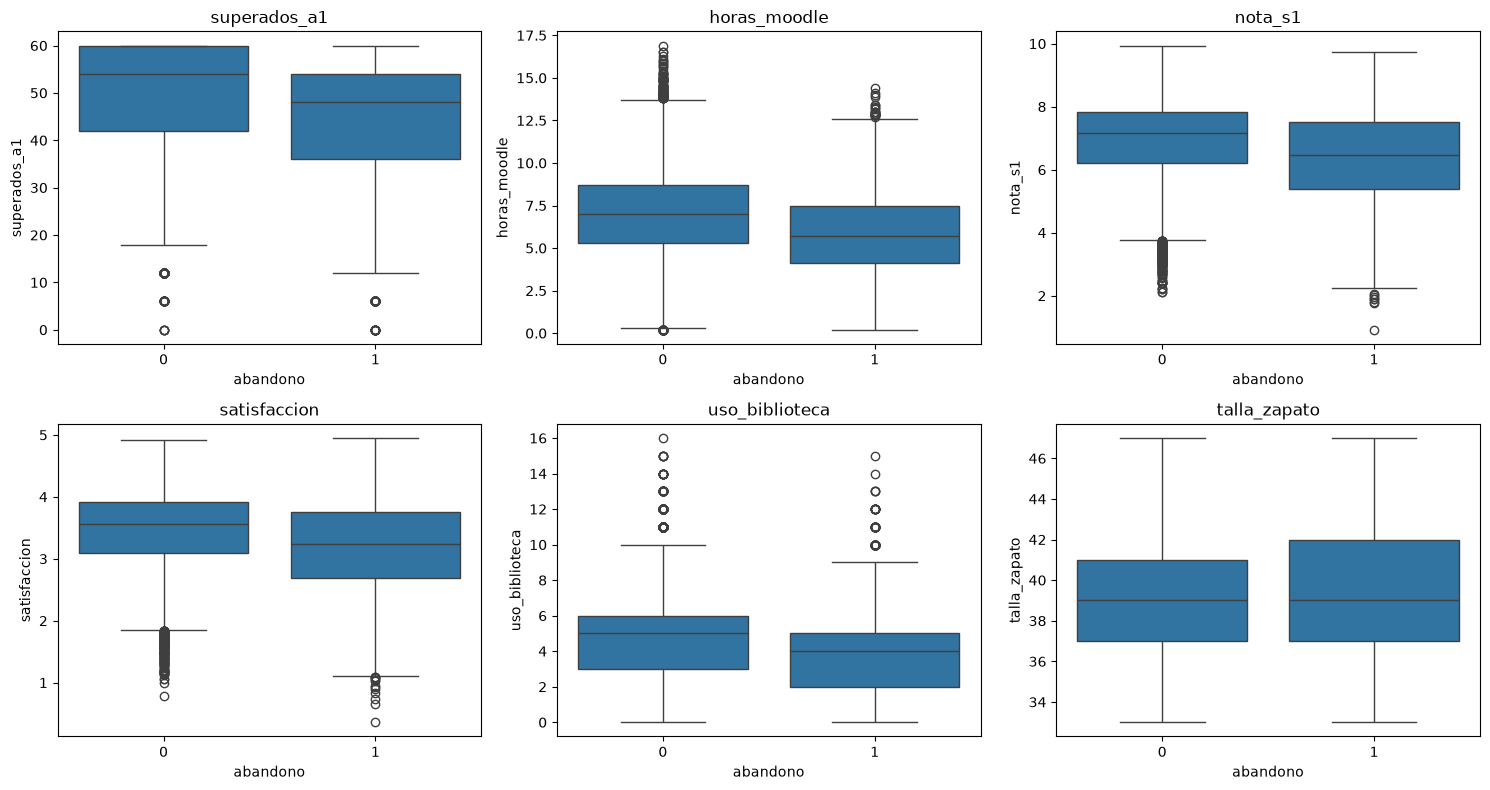

In [53]:
# diagramas de caja de las variables más relacionadas, separados por abandono
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, ['superados_a1', 'horas_moodle', 'nota_s1',
                               'satisfaccion', 'uso_biblioteca', 'talla_zapato']):
    sns.boxplot(data=eda, x='abandono', y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


Elegimos las cinco variables más relacionadas y talla_zapato como ejemplo de variable sin relación. La raya de dentro de cada caja es la mediana: en las cinco primeras, la caja de quienes abandonan (1) está más baja que la de quienes continúan (0), mientras que en talla_zapato las dos cajas están a la misma altura.


#### Conclusión del paso 1

* **Más relacionadas:** superados_a1 (−0,222), horas_moodle (−0,211), nota_s1 (−0,194), satisfaccion (−0,187) y uso_biblioteca (−0,185). Quienes abandonan superan menos créditos (44,6 frente a 50,6), se conectan menos a Moodle (5,8 frente a 7,0 horas) y sacan peor nota (6,4 frente a 6,9).
* **Relación débil:** eventos, tutorias, meses_matriculado, nota_acceso y horas_trabajo.
* **Sin relación:** creditos_a1 (0,004) y numero_fav (0,006).
* **Pendientes del paso 3:** talla_zapato, que no tiene sentido como causa, y meses_matriculado, que puede tener una relación no lineal que la correlación no detecta.

Ninguna correlación es muy alta: el abandono depende de muchas variables a la vez, por eso conviene combinarlas en un modelo.


#### Paso 2: variables categóricas frente a abandono

Calculamos la tasa de abandono de cada categoría. Si cambia mucho de una categoría a otra, la variable ayuda a predecir.


In [54]:
# unificar mayúsculas, tildes y sinónimos de bachillerato (25 formas -> 7 categorías)
eda['bachillerato'] = (eda['bachillerato']
    .str.strip().str.lower()
    .str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('ascii')
    .replace({'salud': 'ciencias de la salud', 'social': 'ciencias sociales',
              'ciencias': 'ciencias puras', 'cientifico': 'ciencias puras',
              'artistico': 'artes'}))

eda['bachillerato'].value_counts()


bachillerato
ciencias puras          10553
ciencias sociales        6907
humanidades              6846
economico                6094
tecnologico              3068
ciencias de la salud     2265
artes                     982
Name: count, dtype: int64

In [55]:
# para cada categórica: nº de categorías y tasa de abandono mínima y máxima
filas = {}
for col in categoricas:
    tasa = eda.groupby(col)['abandono'].mean().mul(100)
    filas[col] = {'categorias': tasa.size, 'tasa_min': tasa.min(), 'tasa_max': tasa.max()}

resumen = pd.DataFrame(filas).T.round(1)
resumen['rango'] = resumen['tasa_max'] - resumen['tasa_min']
resumen.sort_values('rango', ascending=False)


,categorias,tasa_min,tasa_max,rango
titulacion,64.0,5.6,71.1,65.5
bachillerato,7.0,12.9,40.8,27.9
provincia,53.0,17.3,42.1,24.8
via_acceso,4.0,25.9,44.6,18.7
color_fav,140.0,20.3,35.1,14.8
modalidad,2.0,26.4,27.3,0.9


In [56]:
# tasa de abandono y nº de estudiantes por categoría
for col in ['via_acceso', 'bachillerato', 'titulacion', 'provincia', 'color_fav']:
    tabla = eda.groupby(col)['abandono'].agg(['mean', 'count']).sort_values('mean')
    tabla['mean'] = tabla['mean'].mul(100).round(1)
    display(tabla)


,mean,count
via_acceso,,
PAU / Bachillerato,25.9,25642
Ciclo Formativo de Grado Superior,27.4,7737
Titulado universitario,28.9,1493
Mayores de 25 años,44.6,1843


,mean,count
bachillerato,,
ciencias de la salud,12.9,2265
humanidades,25.3,6846
economico,25.5,6094
ciencias sociales,26.0,6907
artes,27.8,982
ciencias puras,29.5,10553
tecnologico,40.8,3068


,mean,count
titulacion,,
Medicina,5.6,827
Fisioterapia,8.2,452
Enfermería,8.4,3216
Historia del Arte,10.4,115
Podología,10.9,487
...,...,...
Geografía y Ordenación del Territorio,64.3,14
Ingeniería de los Recursos Energéticos,66.5,272
Ingeniería de Edificación,66.7,12


,mean,count
provincia,,
Málaga,17.3,81
La Rioja,18.4,76
Girona,19.3,88
Granada,21.2,66
La Coruña,21.6,74
Córdoba,21.9,73
Ciudad,21.9,73
Alicante,22.2,63
Lugo,22.7,66


,mean,count
color_fav,,
Crema,20.3,271
Granate pálido,22.2,279
Violeta oscuro,22.6,257
Azul claro,22.7,278
Negro,22.8,272
...,...,...
Ocre intenso,33.1,245
Rojo oscuro,33.3,264
Púrpura intenso,33.6,262


#### Conclusión del paso 2

La titulación es la categórica que más influye: el abandono va del 5,6 % en Medicina a más del 60 % en algunas ingenierías. También ayudan el bachillerato (salud 12,9 %, tecnológico 40,8 %) y la vía de acceso (Mayores de 25 años, 44,6 % frente al 26-29 % del resto). La provincia aporta poco: las cuatro con más estudiantes tienen tasas parecidas (25-29 %) y las tasas extremas son de provincias con pocos alumnos. La modalidad (26,4 % frente a 27,3 %) y el color favorito no influyen. En el preprocesamiento hay que limpiar bachillerato y eliminar modalidad y color_fav.


#### Paso 3: variables sospechosas

Revisamos meses_matriculado, talla_zapato y numero_fav, que en el paso 1 tenían una relación dudosa.


In [57]:
# tasa de abandono y nº de estudiantes según los meses matriculado
tabla = eda.groupby('meses_matriculado')['abandono'].agg(['mean', 'count'])
tabla['mean'] = tabla['mean'].mul(100).round(1)
tabla.T


meses_matriculado,1,2,3,4,5,6,7,8,9,10,11,12
mean,100.0,51.9,42.1,62.4,71.7,23.2,57.5,67.4,65.8,78.6,62.5,21.6
count,5.0,154.0,737.0,1084.0,1450.0,28143.0,80.0,92.0,114.0,145.0,144.0,4567.0


In [58]:
# meses_matriculado según el año de ingreso, en train (sin duplicados) y en test
anio_train = eda['id'].str.split('-').str[1]
anio_test = df_test['id'].str.split('-').str[1]

tabla = pd.concat([pd.crosstab(anio_train, eda['meses_matriculado']),
                   pd.crosstab(anio_test, df_test['meses_matriculado'])]).fillna(0).astype(int)
tabla.index.name = 'año de ingreso'
tabla


meses_matriculado,1,2,3,4,5,6,7,8,9,10,11,12
año de ingreso,,,,,,,,,,,,
2012,1,29,142,213,283,5171,0,0,0,0,0,0
2013,1,29,107,188,245,4739,0,0,0,0,0,0
2014,0,35,123,162,190,4643,0,0,0,0,0,0
2015,0,19,117,170,203,4333,0,0,0,0,0,0
2016,1,21,116,165,228,4641,0,0,0,0,0,0
2017,2,21,128,163,250,4547,0,0,0,0,0,0
2018,0,0,4,23,51,69,80,92,114,145,144,4567
2019,0,0,8,15,68,73,83,123,122,139,134,4880
2020,0,0,3,25,63,60,109,110,129,129,132,4829


La tabla muestra que meses_matriculado no se mide igual todos los años. De 2012 a 2017 solo toma valores del 1 al 6 y casi todos los estudiantes tienen 6. Desde 2018 llega hasta 12 y casi todos tienen 12. Es decir, hasta 2017 se observaba medio curso y desde 2018 el curso entero.

Esto importa porque el test es de 2019 y 2020, con la escala nueva. Un 6 en 2015 significa que el estudiante llegó al final del periodo, pero un 6 en 2019 significa que solo estuvo medio curso. Si el modelo usa el número tal cual, aprende de los años antiguos que 6 meses es buena señal y se equivoca con esos estudiantes del test (133 en 2019 y 2020).

Por eso en el preprocesamiento no usaremos meses_matriculado directamente, sino la proporción del periodo que ha estado matriculado: los meses divididos entre 6 hasta 2017 y entre 12 desde 2018. Así un 6 de 2015 y un 12 de 2019 valen 1 (periodo completo) y un 6 de 2019 vale 0,5.


In [59]:
# talla_zapato: tasa real frente a la tasa que tocaría solo por la titulación que estudian
eda['tasa_titulacion'] = eda.groupby('titulacion')['abandono'].transform('mean')

tabla = eda.groupby('talla_zapato')[['abandono', 'tasa_titulacion']].mean().mul(100).round(1)
tabla.columns = ['tasa_real', 'tasa_por_titulacion']
eda = eda.drop(columns='tasa_titulacion')
tabla.T


talla_zapato,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47
tasa_real,28.4,22.5,25.1,25.9,25.7,25.9,26.4,27.3,28.9,29.0,30.6,31.3,30.8,29.8,32.9
tasa_por_titulacion,26.1,24.7,25.5,24.9,25.5,25.9,26.6,27.6,28.8,29.9,30.5,31.0,31.2,30.8,30.3


In [60]:
# numero_fav: tasa de abandono por tramos de 10 en 10
tabla = eda.groupby(pd.cut(eda['numero_fav'], bins=range(0, 101, 10)))['abandono'].agg(['mean', 'count'])
tabla['mean'] = tabla['mean'].mul(100).round(1)
tabla.T


numero_fav,"(0, 10]","(10, 20]","(20, 30]","(30, 40]","(40, 50]","(50, 60]","(60, 70]","(70, 80]","(80, 90]","(90, 100]"
mean,27.2,26.8,26.6,26.5,26.9,28.3,27.8,28.2,27.0,27.4
count,3627.0,3690.0,3657.0,3689.0,3685.0,3721.0,3628.0,3701.0,3617.0,3700.0


#### Conclusión del paso 3

En meses_matriculado la relación no es lineal: quienes llegan al final del periodo (6 meses hasta 2017, 12 desde 2018) abandonan alrededor del 22 %, y el resto más del 40 %. Por eso su correlación era baja. Como la escala cambia en 2018, la sustituiremos por proporcion_periodo (meses entre la duración del periodo de su año). Aun así, este dato podría ser fuga, porque quien abandona deja de sumar meses; lo usamos porque también viene en el test.

La relación de talla_zapato se explica por la titulación, y en numero_fav todos los tramos rondan el 27 %, así que eliminamos ambas.


#### Paso 4: variable nueva, la edad

No tenemos la edad, pero sí la fecha de nacimiento y el año de ingreso, que va dentro del id (por ejemplo CR-2018-BCG465).


In [61]:
# edad al entrar = año de ingreso (sacado del id) - año de nacimiento
anio_ingreso = eda['id'].str.split('-').str[1].astype(int)
anio_nacimiento = pd.to_datetime(eda['nacimiento']).dt.year
eda['edad'] = anio_ingreso - anio_nacimiento

print(eda['edad'].describe().round(1))
print('Correlación con abandono:', round(eda['edad'].corr(eda['abandono']), 3))

tramos = pd.cut(eda['edad'], bins=[0, 18, 19, 21, 25, 100], labels=['18 o menos', '19', '20-21', '22-25', 'más de 25'])
tabla = eda.groupby(tramos)['abandono'].agg(['mean', 'count'])
tabla['mean'] = tabla['mean'].mul(100).round(1)
tabla.T


count    36715.0
mean        19.4
std          4.6
min         17.0
25%         18.0
50%         18.0
75%         18.0
max         48.0
Name: edad, dtype: float64
Correlación con abandono: 0.088


edad,18 o menos,19,20-21,22-25,más de 25
mean,26.2,24.0,25.5,29.4,40.0
count,29972.0,533.0,1755.0,1880.0,2575.0


#### Conclusión del paso 4

Hasta los 25 años la tasa de abandono casi no cambia (24-29 %), pero los mayores de 25 abandonan bastante más (40 %). Se parece a lo que vimos con la vía "Mayores de 25 años" (44,6 %), porque en gran parte son las mismas personas. Crearemos la variable edad en el preprocesamiento.


#### Paso 5: comentarios

Cada comentario está formado por varias frases fijas separadas por puntos, así que calculamos la tasa de abandono de cada frase.


In [62]:
# separar cada comentario en frases y calcular la tasa de abandono de cada frase
frases = (eda[['comentarios', 'abandono']]
          .assign(frase=eda['comentarios'].str.lower().str.split(r'\.\s*'))
          .explode('frase'))
frases['frase'] = frases['frase'].str.strip()
frases = frases[frases['frase'] != '']

tabla = frases.groupby('frase')['abandono'].agg(['mean', 'count'])
tabla = tabla[tabla['count'] >= 300].sort_values('mean')
tabla['mean'] = tabla['mean'].mul(100).round(1)
print('Frases distintas:', frases['frase'].nunique(), '| con 300 o más apariciones:', len(tabla))
tabla


Frases distintas: 583 | con 300 o más apariciones: 50


,mean,count
frase,,
muestra gran interes por fisica,11.2,374
su actitud frente a vida personal y estudios es ejemplar,12.8,437
muestra gran interes por troncales,13.6,382
su actitud frente a asistencia y tareas es ejemplar,13.6,469
ha mejorado notablemente en asignaturas basicas,13.8,520
muestra gran interes por matematicas,15.1,443
participa activamente en practicas,15.2,508
participa activamente en tutorias,15.3,412
cumple siempre con practicas,15.3,574


#### Conclusión del paso 5

El contenido de los comentarios sí predice el abandono: las frases positivas ("cumple siempre con trabajos") van con un 11-18 % de abandono, las neutras con un 24-31 % y las negativas ("bajo rendimiento en fisica") con un 36-44 %. En el preprocesamiento convertiremos el texto en números según las palabras que contiene, para que el modelo pueda usarlo.


### 5.6 Conclusión del EDA: decisiones para el preprocesamiento

Antes de nada, eliminamos las 4.371 filas duplicadas.

**Variables que se eliminaron:** id y nombre (son identificadores), nacimiento (la cambiamos por la edad), meses_matriculado (la cambiamos por proporcion_periodo), residencia_id (73 % de huecos y no cambia el abandono), grupo_trabajo (8.382 valores distintos), modalidad y creditos_a1 (no influyen y son redundantes entre sí), numero_fav y color_fav (son ruido) y talla_zapato (su relación se explica por la titulación).

**Variables que se conservaron y como se trataron:**
* nota_acceso, nota_s1, satisfaccion y horas_moodle: pasarlas de texto a número.
* nota_s1 y satisfaccion: rellenar los huecos con la mediana.
* horas_trabajo: 0 si no trabaja y 25 si trabaja pero falta el dato.
* provincia: los huecos pasan a "Desconocida" y "Ciudad" se corrige a "Ciudad Real".
* bachillerato: unificar las 25 formas de escribirlo en 7 categorías.
* comentarios: los huecos pasan a texto vacío y el texto se convierte en números según las palabras que contiene.
* Las numéricas se escalan (los atípicos se quedan porque son valores válidos) y las categóricas se pasan a one-hot.

**Variables nuevas:** sin_nota_s1 (1 si falta la nota del primer semestre, porque esos estudiantes abandonan un 62 %), edad (año de ingreso menos año de nacimiento; los mayores de 25 abandonan un 40 %) y proporcion_periodo (meses matriculado entre 6 hasta 2017 y entre 12 desde 2018; quienes completan el periodo abandonan un 22 % frente a más del 40 %; puede ser fuga de datos).

Despues del análisis, las variables más útiles son titulacion, superados_a1, horas_moodle, nota_s1, satisfaccion, uso_biblioteca, comentarios, bachillerato y via_acceso.


## 6. Preprocesamiento con Pipeline

En este apartado aplicamos las decisiones del EDA (5.6) dentro de un Pipeline de scikit-learn. Así, todo lo que se aprende de los datos (medianas, categorías, palabras...) se aprende solo con los datos de entrenamiento y se aplica igual en validación y en test, sin fuga de datos.

El pipeline tiene tres pasos:

1. **Limpiar:** pasar texto a número, crear las variables nuevas y eliminar las que no sirven.
2. **Preprocesado:** rellenar huecos, escalar las numéricas, pasar las categóricas a one-hot y convertir los comentarios en números.
3. **Modelo:** el árbol de decisión (sección 7).

Antes del pipeline eliminamos los duplicados y separamos las variables predictoras (X) de la variable objetivo (y).


### 6.1 Preparar los datos

Quitamos los duplicados y separamos X e y. Partimos de df_train y no de eda, porque el pipeline tiene que recibir los datos tal como vienen del CSV, igual que vendrá el test.


In [63]:
# quitar duplicados y separar variables predictoras (X) y variable objetivo (y)
datos = df_train.drop_duplicates()

X = datos.drop(columns='abandono')
y = datos['abandono']

print('X:', X.shape)
print('y:', y.shape, '| tasa de abandono:', round(y.mean() * 100, 1), '%')


X: (36715, 26)
y: (36715,) | tasa de abandono: 27.3 %


### 6.2 Función de limpieza

Reunimos en una función todas las transformaciones que no necesitan aprender nada de los datos: convertir texto a número, crear las variables nuevas, arreglar categorías y eliminar columnas. Con FunctionTransformer la convertimos en un paso del pipeline, como en el material de la práctica.


In [64]:
from sklearn.preprocessing import FunctionTransformer

def limpiar(df):
    df = df.copy()

    # 1. columnas numéricas guardadas como texto -> número (5.3)
    for col in ['nota_acceso', 'nota_s1', 'satisfaccion']:
        df[col] = pd.to_numeric(df[col].str.replace(',', '.'))
    df['horas_moodle'] = pd.to_numeric(
        df['horas_moodle'].str.replace(',', '.').str.replace('~', '')
        .str.replace('horas', '').str.replace('h', '').str.strip())

    # 2. variables nuevas (5.2 y 5.5)
    df['sin_nota_s1'] = df['nota_s1'].isna().astype(int)
    anio_ingreso = df['id'].str.split('-').str[1].astype(int)
    df['edad'] = anio_ingreso - pd.to_datetime(df['nacimiento']).dt.year
    # periodo de 6 meses hasta 2017 y de 12 desde 2018 (5.5, paso 3)
    df['proporcion_periodo'] = df['meses_matriculado'] / np.where(anio_ingreso <= 2017, 6, 12)

    # 3. horas_trabajo: 0 si no trabaja, 25 (mediana de los que trabajan) si falta (5.2)
    df.loc[df['trabaja'] == 0, 'horas_trabajo'] = 0
    df['horas_trabajo'] = df['horas_trabajo'].fillna(25)

    # 4. arreglar categorías mal escritas (5.3 y 5.5)
    df['provincia'] = df['provincia'].replace('Ciudad', 'Ciudad Real')
    df['bachillerato'] = (df['bachillerato']
        .str.strip().str.lower()
        .str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('ascii')
        .replace({'salud': 'ciencias de la salud', 'social': 'ciencias sociales',
                  'ciencias': 'ciencias puras', 'cientifico': 'ciencias puras',
                  'artistico': 'artes'}))
    df['comentarios'] = df['comentarios'].fillna('')

    # 5. eliminar las columnas descartadas en el EDA (5.6)
    df = df.drop(columns=['id', 'nombre', 'nacimiento', 'meses_matriculado', 'residencia_id',
                          'grupo_trabajo', 'modalidad', 'creditos_a1', 'numero_fav',
                          'color_fav', 'talla_zapato'])
    return df

limpieza = FunctionTransformer(limpiar)

# comprobar el resultado
X_limpio = limpieza.fit_transform(X)
print(X_limpio.shape)
X_limpio.head()


(36715, 18)


,provincia,titulacion,via_acceso,nota_acceso,bachillerato,trabaja,horas_trabajo,superados_a1,nota_s1,satisfaccion,horas_moodle,uso_biblioteca,eventos,tutorias,comentarios,sin_nota_s1,edad,proporcion_periodo
0,Albacete,Bellas Artes,Ciclo Formativo de Grado Superior,7.09,ciencias sociales,0,0.0,60,8.57,4.15,5.5,3,0,2,,0,23,1.000000
1,Ciudad Real,Doble Grado Derecho-ade,PAU / Bachillerato,6.79,humanidades,0,0.0,24,4.75,2.51,9.1,8,1,2,Situacion academica estable. Respeta las regla...,0,18,1.000000
2,Ciudad Real,Derecho,Mayores de 25 años,5.00,humanidades,1,40.0,42,6.19,3.11,3.9,9,0,0,Ausencias injustificadas en seminarios. No int...,0,46,0.833333
3,Albacete,Medicina,Ciclo Formativo de Grado Superior,6.41,ciencias puras,0,0.0,42,5.14,2.51,8.2,7,3,3,Uso habitual de la plataforma Moodle. Uso habi...,0,17,1.000000
4,Ciudad Real,Ingeniería Informática,PAU / Bachillerato,9.05,ciencias puras,0,0.0,6,2.68,1.16,6.2,1,2,0,Uso habitual de la plataforma Moodle. Interacc...,0,17,1.000000


### 6.3 Tratamiento por tipo de columna

Cada grupo de columnas tiene su tratamiento: las numéricas se rellenan con la mediana y se escalan, las categóricas se rellenan con "Desconocida" y se pasan a one-hot, y comentarios se convierte en una columna por palabra con CountVectorizer.

Al árbol de decisión no le afecta el escalado, porque solo compara cada variable con un umbral. Lo mantenemos para poder probar en la Práctica 2 otros modelos que sí lo necesitan, como KNN.



In [65]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer

# columnas que salen de limpiar(), separadas por tipo
cols_num = ['nota_acceso', 'nota_s1', 'satisfaccion', 'horas_moodle', 'horas_trabajo',
            'superados_a1', 'uso_biblioteca', 'eventos', 'tutorias', 'trabaja',
            'sin_nota_s1', 'edad', 'proporcion_periodo']
cols_cat = ['provincia', 'titulacion', 'via_acceso', 'bachillerato']

# numéricas: huecos -> mediana, después escalar
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# categóricas: huecos -> 'Desconocida', después one-hot
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Desconocida')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# cada grupo de columnas con su tratamiento; comentarios -> una columna por palabra
preprocesado = ColumnTransformer([
    ('num', num_pipe, cols_num),
    ('cat', cat_pipe, cols_cat),
    ('txt', CountVectorizer(binary=True), 'comentarios')
])

# comprobar el resultado
X_prep = preprocesado.fit_transform(X_limpio)
print('Antes:', X_limpio.shape, '-> después:', X_prep.shape)
print('Palabras de comentarios:', len(preprocesado.named_transformers_['txt'].get_feature_names_out()))


Antes: (36715, 18) -> después: (36715, 1086)
Palabras de comentarios: 945


### 6.4 pipeline completo

Unimos la limpiez, el tratamiento por columnas y el modelo en un unico Pipeline, como modelo usamos un arbol de decision de scikit-learn

In [66]:
from sklearn.tree import DecisionTreeClassifier

# pipeline completo: limpieza -> tratamiento por columnas -> modelo
pipeline = Pipeline([
    ('limpiar', limpieza),
    ('preprocesado', preprocesado),
    ('modelo', DecisionTreeClassifier(random_state=42))
])

pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('limpiar', ...), ('preprocesado', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function lim...t 0x11ba2fba0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDict

## 7. Modelización y validación

### 7.1 Validación cruzada con varias métricas

Evaluamos el pipeline con validación cruzada estratificada de 5 particiones y cuatro métricas: F1 (la de Kaggle), precisión, recall y accuracy.


In [67]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5 particiones que mantienen el 27 % de abandono en cada una
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['f1', 'precision', 'recall', 'accuracy']

resultados = cross_validate(pipeline, X, y, cv=cv, scoring=metricas, return_train_score=True)

# media y desviación de cada métrica, en entrenamiento y en validación
tabla = pd.DataFrame({
    'entrenamiento': [resultados[f'train_{m}'].mean() for m in metricas],
    'validacion': [resultados[f'test_{m}'].mean() for m in metricas],
    'desviacion_validacion': [resultados[f'test_{m}'].std() for m in metricas],
}, index=metricas).round(3)
tabla


,entrenamiento,validacion,desviacion_validacion
f1,1.0,0.448,0.005
precision,1.0,0.451,0.008
recall,1.0,0.446,0.005
accuracy,1.0,0.701,0.005


### 7.2 Comparación de modelos

Comparamos varias configuraciones del árbol para reducir el sobreajuste, y repetimos la evaluación con duplicados para ver el efecto de la fuga de datos.


In [68]:
from sklearn.base import clone

# versiones del pipeline a comparar: solo cambia la configuración del árbol
versiones = {
    'Arbol sin limite': {},
    'Arbol max_depth=10': {'modelo__max_depth': 10},
    'Arbol max_depth=10 + class_weight': {'modelo__max_depth': 10, 'modelo__class_weight': 'balanced'},
}

# datos con duplicados, para ver la fuga de datos
X_dup = df_train.drop(columns='abandono')
y_dup = df_train['abandono']

def evaluar(params, X_eval, y_eval):
    modelo = clone(pipeline).set_params(**params)
    r = cross_validate(modelo, X_eval, y_eval, cv=cv, scoring=metricas, return_train_score=True)
    fila = {m: r[f'test_{m}'].mean() for m in metricas}
    fila['f1_entrenamiento'] = r['train_f1'].mean()
    return fila

comparacion = {nombre: evaluar(params, X, y) for nombre, params in versiones.items()}
comparacion['Arbol sin limite CON duplicados'] = evaluar({}, X_dup, y_dup)

pd.DataFrame(comparacion).T.round(3)


,f1,precision,recall,accuracy,f1_entrenamiento
Arbol sin limite,0.448,0.451,0.446,0.701,1.000
Arbol max_depth=10,0.448,0.624,0.351,0.765,0.547
Arbol max_depth=10 + class_weight,0.537,0.453,0.661,0.689,0.609
Arbol sin limite CON duplicados,0.675,0.640,0.713,0.764,1.000


In [69]:
# ¿por qué max_depth=10? probamos varias profundidades, todas con class_weight='balanced'
profundidades = {}
for d in [3, 5, 7, 10, 15]:
    profundidades[f'max_depth={d}'] = evaluar({'modelo__max_depth': d, 'modelo__class_weight': 'balanced'}, X, y)

pd.DataFrame(profundidades).T[['f1', 'precision', 'recall', 'f1_entrenamiento']].round(3)


,f1,precision,recall,f1_entrenamiento
max_depth=3,0.497,0.492,0.502,0.500
max_depth=5,0.524,0.461,0.613,0.534
max_depth=7,0.533,0.449,0.660,0.561
max_depth=10,0.537,0.453,0.661,0.609
max_depth=15,0.527,0.457,0.623,0.705


### 7.3 Conclusión

Usamos validación cruzada estratificada de 5 particiones con el pipeline completo. Los resultados apenas cambian entre vueltas (desviación de 0,005), así que la estimación es estable.

La accuracy no sirve como métrica principal, porque diciendo siempre "no abandona" ya se acierta un 72,7 %. Por eso nos fijamos en el F1, que combina precisión y recall.

El árbol sin límite memoriza los datos: F1 de 1,0 en entrenamiento y de 0,448 en validación. Limitar la profundidad a 10 reduce el sobreajuste, pero detecta pocos abandonos (recall 0,351). Al añadir class_weight='balanced' el F1 sube a 0,537 y el recall a 0,661: detecta dos de cada tres estudiantes que abandonan. Al probar varias profundidades, el F1 de validación sube hasta max_depth=10 y baja con 15, mientras el de entrenamiento sigue subiendo (0,705), así que a partir de ahí hay sobreajuste. El mejor modelo es el árbol con max_depth=10 y class_weight='balanced'.

#### Comprobación de fugas de datos

* Todo lo que se aprende de los datos (medianas, escalado, categorías y palabras) está dentro del pipeline, así que en cada vuelta se calcula solo con la parte de entrenamiento.
* Con las filas duplicadas el F1 sube a 0,675, pero es falso, porque la misma fila cae en entrenamiento y en validación. Por eso se eliminaron antes de entrenar.
* La diferencia entre entrenamiento (0,609) y validación (0,537) indica que el modelo no está viendo los datos de validación.
* Quedan dos puntos a vigilar: el 25 de horas_trabajo se calculó con todo el train (es un único valor fijo, su efecto es mínimo) y proporcion_periodo podría ser fuga, aunque la usamos porque viene también en el test.


### 7.4 Predicciones de kaggle

In [70]:
# modelo final: el mejor de la validación, entrenado con todos los datos sin duplicados
modelo_final = clone(pipeline).set_params(modelo__max_depth=10, modelo__class_weight='balanced')
modelo_final.fit(X, y)

# predicciones para el test en el formato de sample_submission (id, abandono)
prediccion = pd.DataFrame({'id': df_test['id'], 'abandono': modelo_final.predict(df_test)})
prediccion.to_csv('prediccion_kaggle.csv', index=False)

print(prediccion.shape, '| abandono predicho:', round(prediccion['abandono'].mean() * 100, 1), '%')
prediccion.head()


(11234, 2) | abandono predicho: 38.7 %


,id,abandono
0,CU-2019-RFV844,0
1,AB-2020-RR266,1
2,CR-2019-FFC269,0
3,AB-2020-OFC312,1
4,CR-2019-MRP759,1
